<a href="https://colab.research.google.com/github/KrithikChidM/PrmlLab/blob/main/Lab6/code.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import math
import random
import numpy as np
import matplotlib.pyplot as plt

random.seed(42)

N = 1500
K = 3
num_classes = 2
weights = [0.3, 0.4, 0.3]

In [2]:
means = [
    [[-5, -2], [-2, 3], [1, -2]],
    [[4, 3], [7, -1], [9, 4]]
]

scales = [0.8, 1.0, 0.9]

In [3]:
def uniform():
    return max(random.random(), 1e-12)

def box_muller():
    u1 = uniform()
    u2 = uniform()
    r = math.sqrt(-2 * math.log(u1))
    theta = 2 * math.pi * u2
    z1 = r * math.cos(theta)
    z2 = r * math.sin(theta)
    return z1, z2

In [4]:
def gaussian_density(x, mean, C):
    a, b = C[0]
    c, d = C[1]
    det = a*d - b*c

    inv = [
        [d/det, -b/det],
        [-c/det, a/det]
    ]

    dx = x[0] - mean[0]
    dy = x[1] - mean[1]
    q = dx*(inv[0][0]*dx + inv[0][1]*dy) + \
        dy*(inv[1][0]*dx + inv[1][1]*dy)

    return math.exp(-0.5*q) / (2*math.pi*math.sqrt(det))

# Example: standard 2D normal density at the origin
x = [0, 0]
mu = [0, 0]
C = [[1, 0], [0, 1]]
print(gaussian_density(x, mu, C))

0.15915494309189535


In [5]:
def gmm_density(x, means, covs, weights):
    p = 0
    for i in range(len(weights)):
        p += weights[i] * gaussian_density(x, means[i], covs[i])
    return p

In [6]:
def generate_component(mean, C):
    z1, z2 = box_muller()
    a, b = C[0]
    c, d = C[1]
    l11 = math.sqrt(a)
    l21 = c / l11
    l22 = math.sqrt(max(d - l21*l21, 1e-12))
    x1 = mean[0] + l11*z1
    x2 = mean[1] + l21*z1 + l22*z2
    return [x1, x2]

In [7]:
def generate_gmm_data(means, covs, weights, n):
    X = []
    for _ in range(n):
        u = uniform()
        if u < weights[0]:
            k = 0
        elif u < weights[0] + weights[1]:
            k = 1
        else:
            k = 2
        X.append(generate_component(means[k], covs[k]))
    return np.array(X)

In [8]:
def make_covariances(kind, scales):
    covs = []
    for s in scales:
        if kind == "Spherical":
            C = [[s*s, 0], [0, s*s]]
        elif kind == "Diagonal":
            C = [[s*s, 0], [0, (0.7*s)**2]]
        else:
            C = [[s*s, 0.6*s*s], [0.6*s*s, 1.4*s*s]]
        covs.append(C)
    return covs

In [9]:
covariance_types = ["Spherical", "Diagonal", "Full"]
class0 = []
class0_d = []
class1 = []
class1_d = []

i = 0
for kind in covariance_types:
    covs = make_covariances(kind, scales)

    print("\nCovariance Type:", kind)

    for cls in range(num_classes):
        X = generate_gmm_data(means[cls], covs, weights, N)

        densities = [
            gmm_density(x, means[cls], covs, weights)
            for x in X
        ]

        print("\nClass", cls + 1)
        print("GMM density at sample point:",
              gmm_density(X[0], means[cls], covs, weights))
        print("Mean GMM density: {:.8f}".format(
            sum(densities) / len(densities)
        ))
        print("Minimum GMM density: {:.8e}".format(min(densities)))
        print("Maximum GMM density: {:.8e}".format(max(densities)))
        if i%2 == 0:
            class0.append(X)
            class0_d.append(densities)
        else:
            class1.append(X)
            class1_d.append(densities)
        i += 1


Covariance Type: Spherical

Class 1
GMM density at sample point: 0.0015922341296595495
Mean GMM density: 0.03253242
Minimum GMM density: 1.08044229e-05
Maximum GMM density: 7.45526046e-02

Class 2
GMM density at sample point: 0.0028678604121236445
Mean GMM density: 0.03205502
Minimum GMM density: 5.04369786e-06
Maximum GMM density: 7.45088479e-02

Covariance Type: Diagonal

Class 1
GMM density at sample point: 0.07748818514159989
Mean GMM density: 0.04562166
Minimum GMM density: 2.72229967e-04
Maximum GMM density: 1.06321752e-01

Class 2
GMM density at sample point: 0.09955591171809469
Mean GMM density: 0.04660568
Minimum GMM density: 8.44993811e-06
Maximum GMM density: 1.06379273e-01

Covariance Type: Full

Class 1
GMM density at sample point: 0.044369429520393584
Mean GMM density: 0.03181247
Minimum GMM density: 4.44587586e-05
Maximum GMM density: 7.31123591e-02

Class 2
GMM density at sample point: 0.043920549687880985
Mean GMM density: 0.03258092
Minimum GMM density: 3.90906944e-0

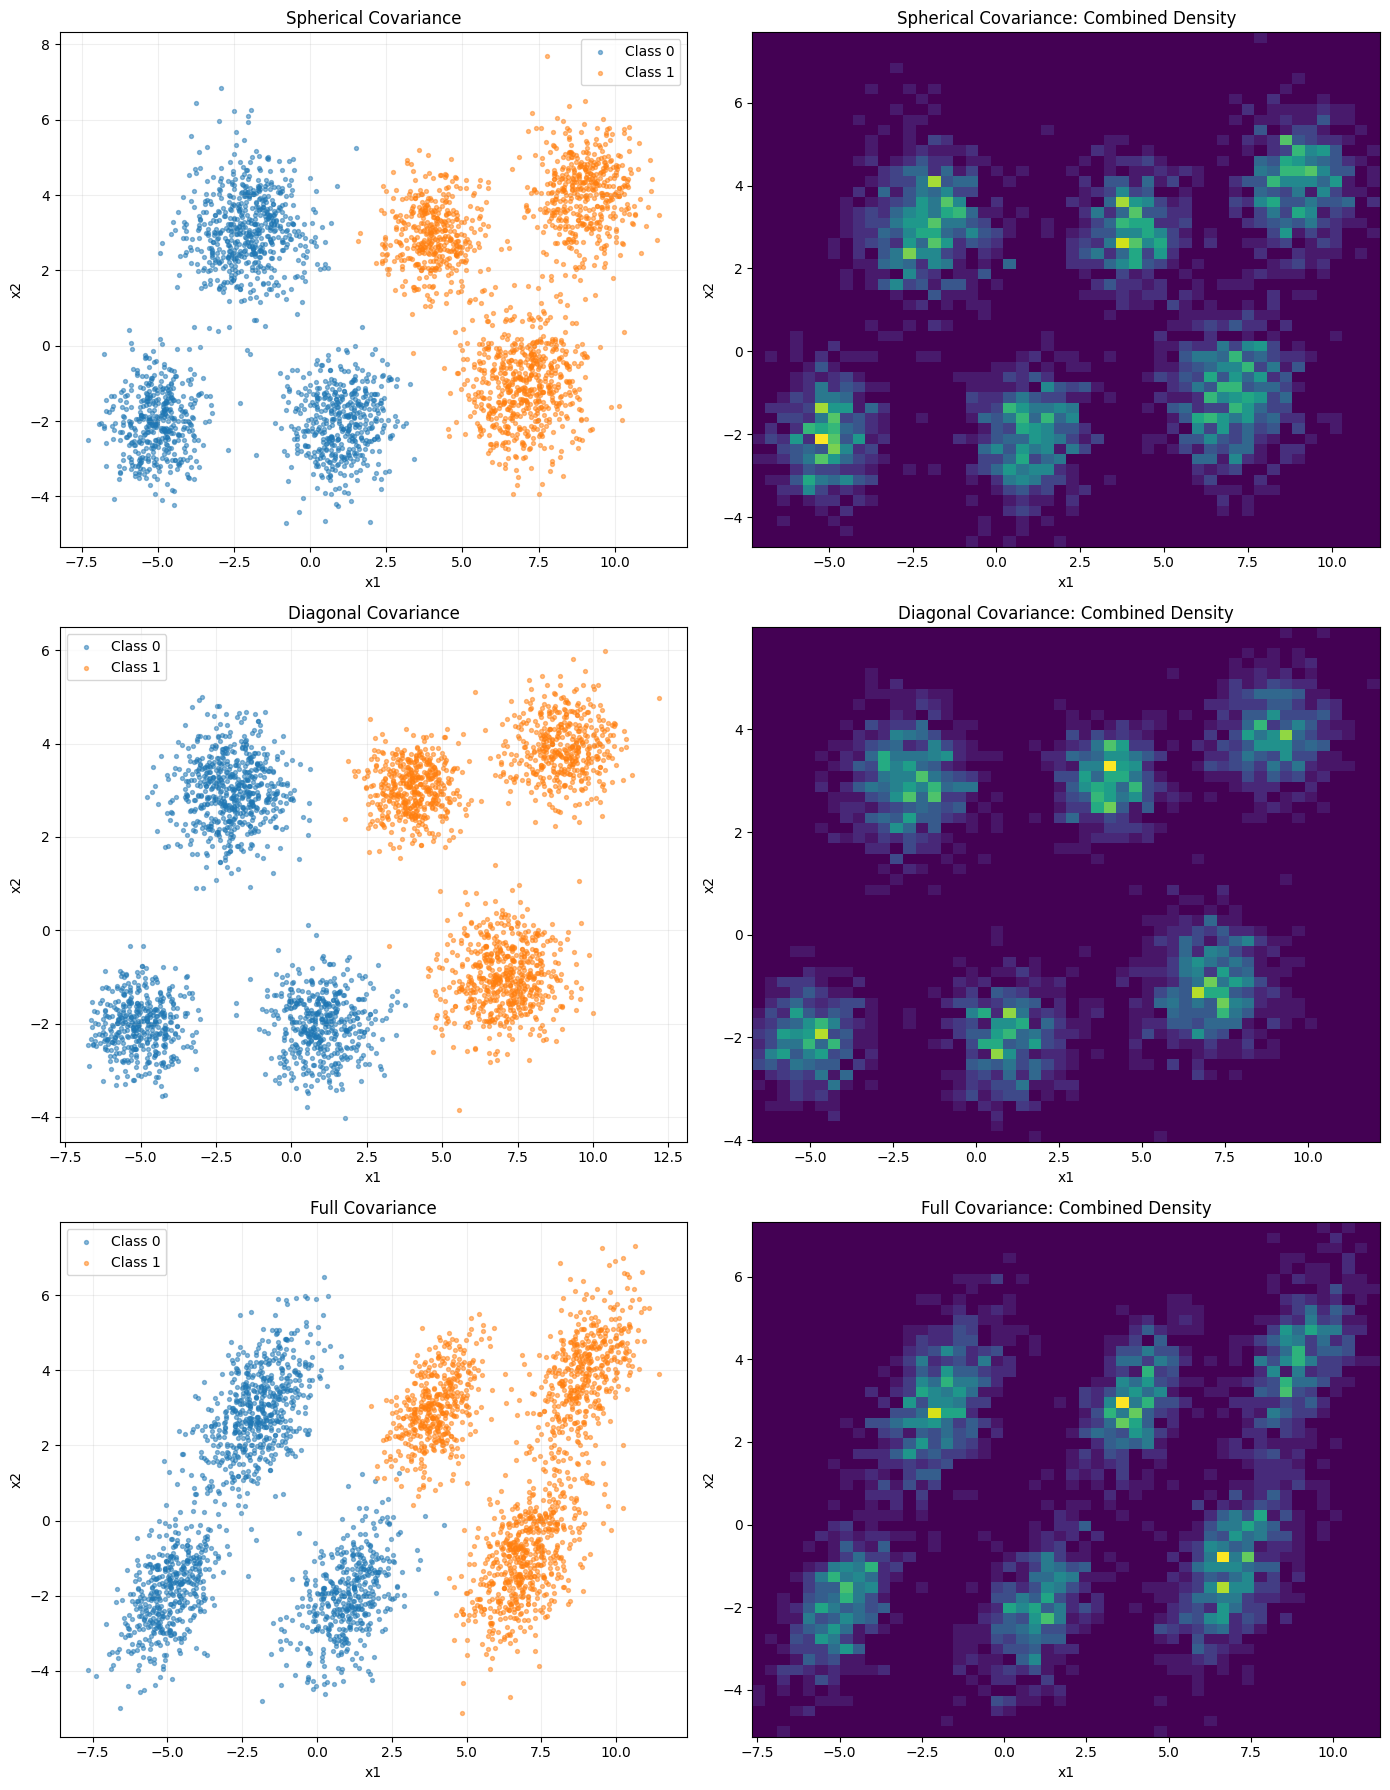

In [11]:
covariance_types = ["Spherical", "Diagonal", "Full"]

fig, axes = plt.subplots(3, 2, figsize=(14, 18))

for i in range(3):
    X0 = class0[i]
    X1 = class1[i]

    axes[i, 0].scatter(X0[:, 0], X0[:, 1], s=8, alpha=0.5, label="Class 0")
    axes[i, 0].scatter(X1[:, 0], X1[:, 1], s=8, alpha=0.5, label="Class 1")
    axes[i, 0].set_title(covariance_types[i] + " Covariance")
    axes[i, 0].set_xlabel("x1")
    axes[i, 0].set_ylabel("x2")
    axes[i, 0].legend()
    axes[i, 0].grid(alpha=0.2)

    x_values = np.vstack([X0, X1])
    axes[i, 1].hist2d(x_values[:, 0], x_values[:, 1], bins=50)
    axes[i, 1].set_title(covariance_types[i] + " Covariance: Combined Density")
    axes[i, 1].set_xlabel("x1")
    axes[i, 1].set_ylabel("x2")

plt.tight_layout()
plt.show()